In [3]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pointbiserialr, mannwhitneyu, chi2_contingency

from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, recall_score, precision_score

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

import xgboost as xgb

try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False

pd.set_option('display.max_columns', 100)

TARGET = 'PCOS (Y/N)'
SEED = 42
RANDOM_STATE = SEED

IMPOSSIBLE = {
    'Pulse rate(bpm)': (40, 200),
    'BP _Systolic (mmHg)': (70, 250),
    'BP _Diastolic (mmHg)': (40, 150),
    'FSH(mIU/mL)': (0, 100),
    'LH(mIU/mL)': (0, 100),
    'Vit D3 (ng/mL)': (0, 200),
}

In [4]:
target = TARGET
df = pd.read_csv('augmented_pcos.csv')
df.columns = df.columns.str.strip()

real = pd.read_csv('pcos_clean.csv')
real.columns = real.columns.str.strip()
row_key = lambda d: d[list(real.columns)].round(4).astype(str).agg('|'.join, axis=1)
df['is_real'] = row_key(df).isin(set(row_key(real))).values

print(df.shape, '| real:', int(df['is_real'].sum()), '| synthetic:', int((~df['is_real']).sum()))
print('PCOS rate by origin:'); print(df.groupby('is_real')[target].mean().round(3).rename({True: 'real', False: 'synthetic'}))
df.head()

(2041, 43) | real: 541 | synthetic: 1500
PCOS rate by origin:
is_real
synthetic    0.235
real         0.327
Name: PCOS (Y/N), dtype: float64


,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),Hb(g/dl),Cycle(R/I),Cycle length(days),Marraige Status (Yrs),Pregnant(Y/N),No. of aborptions,I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),FSH(mIU/mL),LH(mIU/mL),FSH/LH,Hip(inch),Waist(inch),Waist:Hip Ratio,TSH (mIU/L),AMH(ng/mL),PRL(ng/mL),Vit D3 (ng/mL),PRG(ng/mL),RBS(mg/dl),Weight gain(Y/N),hair growth(Y/N),Skin darkening (Y/N),Hair loss(Y/N),Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm),is_real
0,1,41,64.6,162.402,24.013345,11,72,18,10.56,4,2,8.6,0,0,261.144,45.050,6.565,4.729,0.271371,36,36,0.961737,3.423,1.670,18.95,7.370,0.341,80.1,0,0,1,0,1,1.0,0,110,80,12,12,19.5,17.61,6.65,False
1,0,35,55.7,150.309,17.385120,15,79,18,9.86,4,2,13.1,1,0,1412.996,350.965,6.336,1.186,2.608660,30,34,0.890656,1.958,4.056,48.35,34.725,0.254,81.8,0,0,1,1,1,1.0,0,120,80,10,10,14.8,13.75,8.67,False
2,1,24,46.3,164.695,18.951993,15,72,18,11.41,2,5,6.6,0,0,262.937,0.990,11.190,1.701,0.228261,36,31,0.937540,2.090,18.093,35.47,13.836,0.316,97.9,0,0,1,1,1,1.0,0,110,80,11,11,19.4,18.48,10.23,False
3,1,39,62.5,148.676,26.710174,15,72,18,11.56,4,4,9.6,0,0,115.249,0.990,7.889,1.310,0.228261,44,38,0.918291,0.363,11.315,17.01,24.571,0.416,101.0,1,1,1,1,1,1.0,0,120,80,19,13,13.7,14.23,6.92,False
4,0,32,52.0,163.000,19.600000,13,70,24,10.80,2,6,4.0,0,0,1.990,1.990,1.350,0.370,3.648649,30,28,0.933333,5.040,2.300,14.86,19.300,0.250,108.0,0,0,0,0,0,1.0,0,120,80,3,1,18.0,17.00,7.30,True


In [5]:
id_like = [c for c in df.columns if df[c].nunique() == len(df)]
id_like

[]

In [6]:
df.dtypes

PCOS (Y/N)                  int64
Age (yrs)                   int64
Weight (Kg)               float64
Height(Cm)                float64
BMI                       float64
Blood Group                 int64
Pulse rate(bpm)             int64
RR (breaths/min)            int64
Hb(g/dl)                  float64
Cycle(R/I)                  int64
Cycle length(days)          int64
Marraige Status (Yrs)     float64
Pregnant(Y/N)               int64
No. of aborptions           int64
I   beta-HCG(mIU/mL)      float64
II    beta-HCG(mIU/mL)    float64
FSH(mIU/mL)               float64
LH(mIU/mL)                float64
FSH/LH                    float64
Hip(inch)                   int64
Waist(inch)                 int64
Waist:Hip Ratio           float64
TSH (mIU/L)               float64
AMH(ng/mL)                float64
PRL(ng/mL)                float64
Vit D3 (ng/mL)            float64
PRG(ng/mL)                float64
RBS(mg/dl)                float64
Weight gain(Y/N)            int64
hair growth(Y/

In [7]:
df.drop(columns='is_real').describe().T

,count,mean,std,min,25%,50%,75%,max
PCOS (Y/N),2041.0,0.259187,0.438296,0.000000,0.000000,0.000000,1.000000,1.000000
Age (yrs),2041.0,30.991671,5.092134,20.000000,27.000000,31.000000,35.000000,48.000000
Weight (Kg),2041.0,59.043900,9.260514,31.000000,53.000000,59.000000,64.800000,108.000000
Height(Cm),2041.0,156.328837,5.761531,137.000000,152.000000,156.066000,160.702000,180.000000
BMI,2041.0,24.875693,3.907045,12.417882,22.223224,24.609410,27.585297,38.900000
Blood Group,2041.0,14.328760,1.390867,11.000000,13.000000,15.000000,15.000000,18.000000
Pulse rate(bpm),2041.0,72.507104,2.477363,13.000000,72.000000,72.000000,72.000000,82.000000
RR (breaths/min),2041.0,18.681529,1.185077,16.000000,18.000000,18.000000,20.000000,28.000000
Hb(g/dl),2041.0,10.838466,0.629507,8.500000,10.450000,10.770000,11.100000,14.800000
Cycle(R/I),2041.0,2.359138,0.768801,2.000000,2.000000,2.000000,2.000000,5.000000


In [8]:
df.isnull().sum().sum()

np.int64(0)

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
(df['I   beta-HCG(mIU/mL)'] == 1.99).sum(), (df['II    beta-HCG(mIU/mL)'] == 1.99).sum()

(np.int64(191), np.int64(308))

In [11]:
df['Cycle(R/I)'].value_counts()

Cycle(R/I)
2    1675
4     365
5       1
Name: count, dtype: int64

In [12]:
df[['Pulse rate(bpm)', 'BP _Systolic (mmHg)', 'BP _Diastolic (mmHg)', 'Vit D3 (ng/mL)', 'FSH(mIU/mL)']].describe().loc[['min','max']]

,Pulse rate(bpm),BP _Systolic (mmHg),BP _Diastolic (mmHg),Vit D3 (ng/mL),FSH(mIU/mL)
min,13.0,12.0,8.0,0.00,0.21
max,82.0,140.0,100.0,6014.66,5052.00


In [13]:
bad = {c: int(((df[c] < lo) | (df[c] > hi)).sum()) for c, (lo, hi) in IMPOSSIBLE.items()}
print('impossible values found:', bad)

for c, (lo, hi) in IMPOSSIBLE.items():
    df.loc[(df[c] < lo) | (df[c] > hi), c] = np.nan

df['BMI'] = df['Weight (Kg)'] / (df['Height(Cm)'] / 100) ** 2
df['Waist:Hip Ratio'] = df['Waist(inch)'] / df['Hip(inch)']
df['FSH/LH'] = (df['FSH(mIU/mL)'] / df['LH(mIU/mL)']).replace([np.inf, -np.inf], np.nan)

print('NaNs after cleaning:')
print(df.isnull().sum()[df.isnull().sum() > 0])

_num = df.select_dtypes(include=[np.number]).columns.drop('is_real', errors='ignore')
df_stat = df.copy()
df_stat[_num] = df_stat[_num].fillna(df_stat[_num].median())

impossible values found: {'Pulse rate(bpm)': 2, 'BP _Systolic (mmHg)': 1, 'BP _Diastolic (mmHg)': 1, 'FSH(mIU/mL)': 1, 'LH(mIU/mL)': 1, 'Vit D3 (ng/mL)': 2}
NaNs after cleaning:
Pulse rate(bpm)         2
FSH(mIU/mL)             1
LH(mIU/mL)              1
FSH/LH                  2
Vit D3 (ng/mL)          2
BP _Systolic (mmHg)     1
BP _Diastolic (mmHg)    1
dtype: int64


In [14]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.drop('is_real', errors='ignore').tolist()
flag_cols = ['PCOS (Y/N)', 'Pregnant(Y/N)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)',
             'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'Cycle(R/I)', 'Blood Group']
continuous_cols = [c for c in numeric_cols if c not in flag_cols]

q1 = df[continuous_cols].quantile(0.25)
q3 = df[continuous_cols].quantile(0.75)
iqr = q3 - q1
outlier_count = ((df[continuous_cols] < (q1 - 1.5*iqr)) | (df[continuous_cols] > (q3 + 1.5*iqr))).sum()
outlier_count.sort_values(ascending=False).head(10)

Cycle length(days)        599
Pulse rate(bpm)           392
BP _Diastolic (mmHg)      246
FSH/LH                    226
AMH(ng/mL)                215
II    beta-HCG(mIU/mL)    140
TSH (mIU/L)               115
RBS(mg/dl)                111
No. of aborptions         110
Hb(g/dl)                   98
dtype: int64

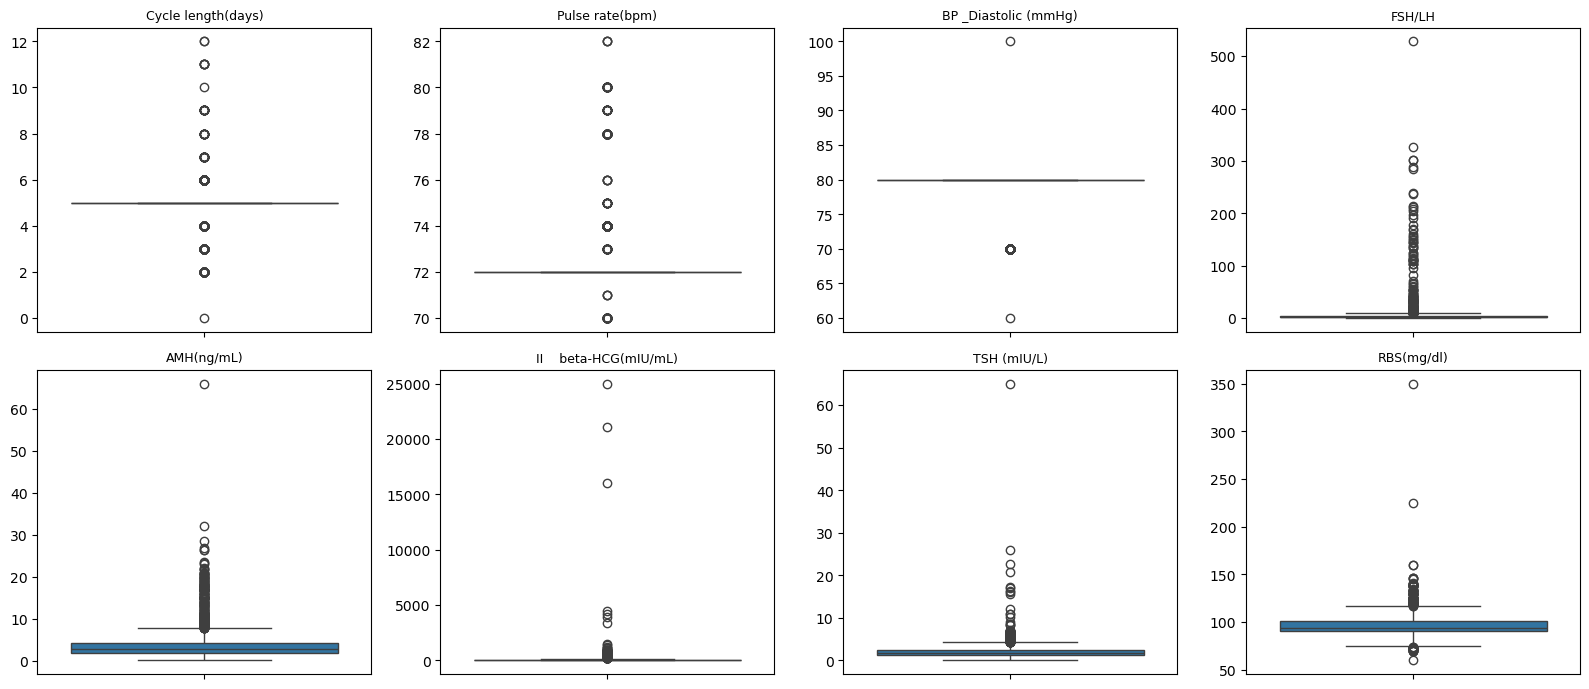

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flatten(), outlier_count.sort_values(ascending=False).head(8).index):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c, fontsize=9)
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

In [16]:
target = 'PCOS (Y/N)'
df[target].value_counts()

PCOS (Y/N)
0    1512
1     529
Name: count, dtype: int64

In [17]:
df[target].value_counts(normalize=True) * 100

PCOS (Y/N)
0    74.081333
1    25.918667
Name: proportion, dtype: float64

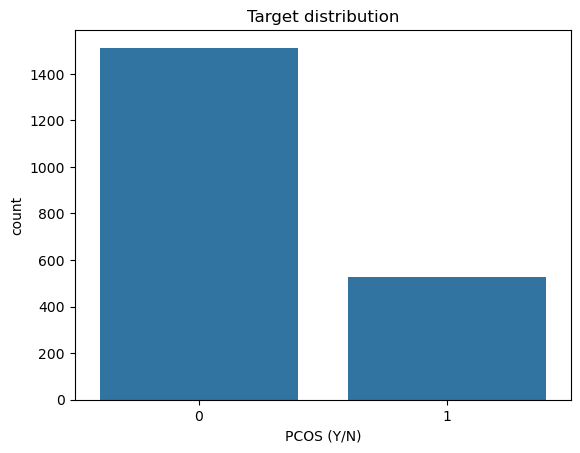

In [18]:
sns.countplot(x=df[target])
plt.title('Target distribution')
plt.show()

In [19]:
summary = df[continuous_cols].agg(['mean', 'median', 'std', 'min', 'max']).T
summary['skew'] = df[continuous_cols].skew()
summary.sort_values('skew', ascending=False).round(2)

,mean,median,std,min,max,skew
PRG(ng/mL),0.41,0.33,1.97,0.05,85.00,40.14
II beta-HCG(mIU/mL),95.97,10.41,833.10,0.99,25000.00,24.63
TSH (mIU/L),2.14,1.83,2.14,0.04,65.00,15.04
I beta-HCG(mIU/mL),282.20,98.06,1742.88,1.30,32460.97,14.74
FSH/LH,7.91,2.20,28.41,0.02,528.28,8.60
FSH(mIU/mL),4.87,4.70,3.25,0.21,65.40,6.55
No. of aborptions,0.08,0.00,0.39,0.00,5.00,6.13
RBS(mg/dl),96.70,93.90,13.35,60.00,350.00,4.37
AMH(ng/mL),3.94,2.81,4.19,0.10,66.00,3.89
Pulse rate(bpm),72.56,72.00,1.72,70.00,82.00,2.96


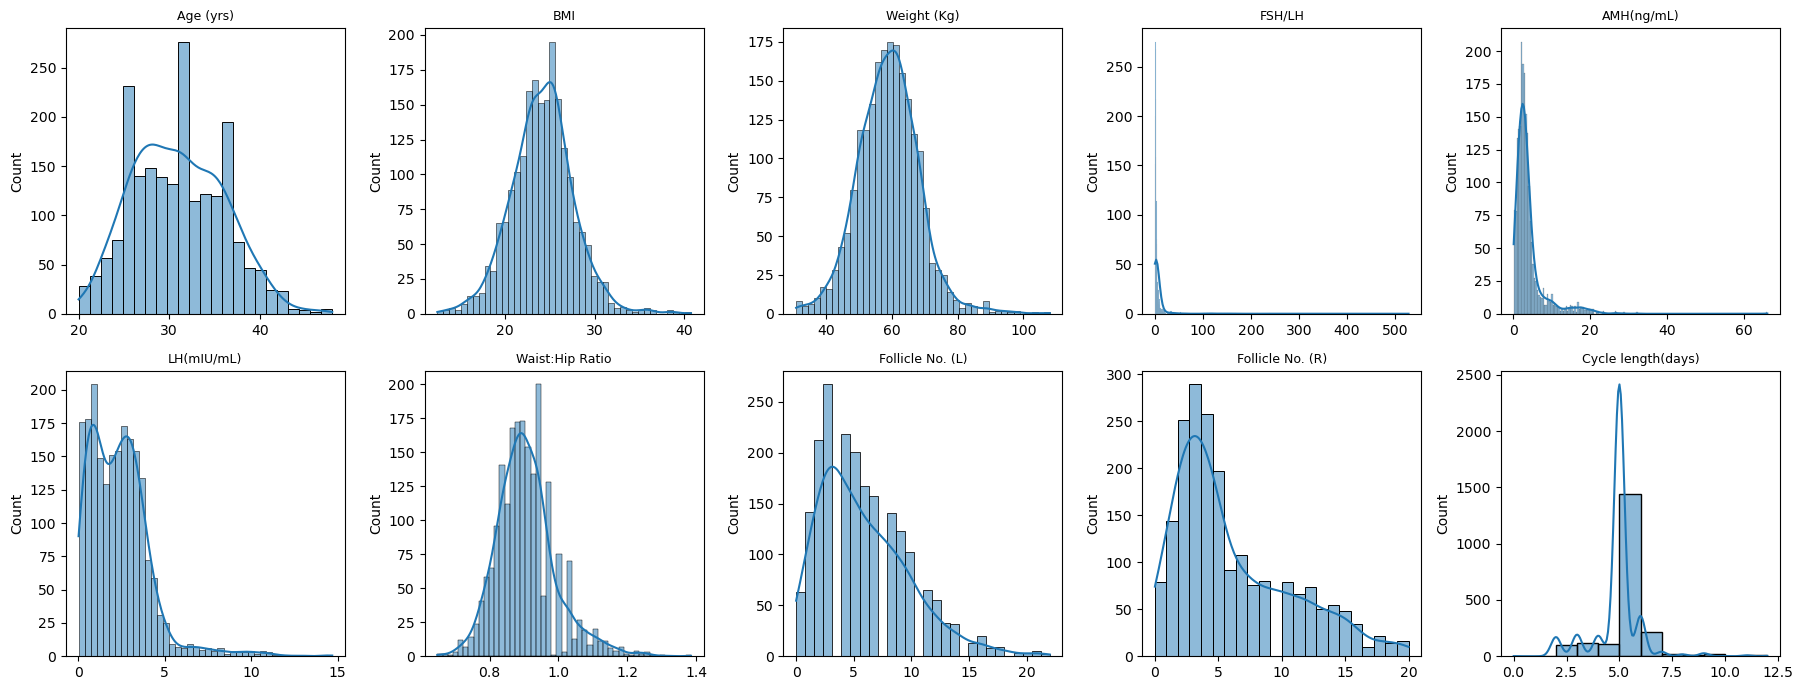

In [20]:
key_numeric = ['Age (yrs)', 'BMI', 'Weight (Kg)', 'FSH/LH', 'AMH(ng/mL)', 'LH(mIU/mL)',
               'Waist:Hip Ratio', 'Follicle No. (L)', 'Follicle No. (R)', 'Cycle length(days)']

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, c in zip(axes.flatten(), key_numeric):
    sns.histplot(df[c], kde=True, ax=ax)
    ax.set_title(c, fontsize=9)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

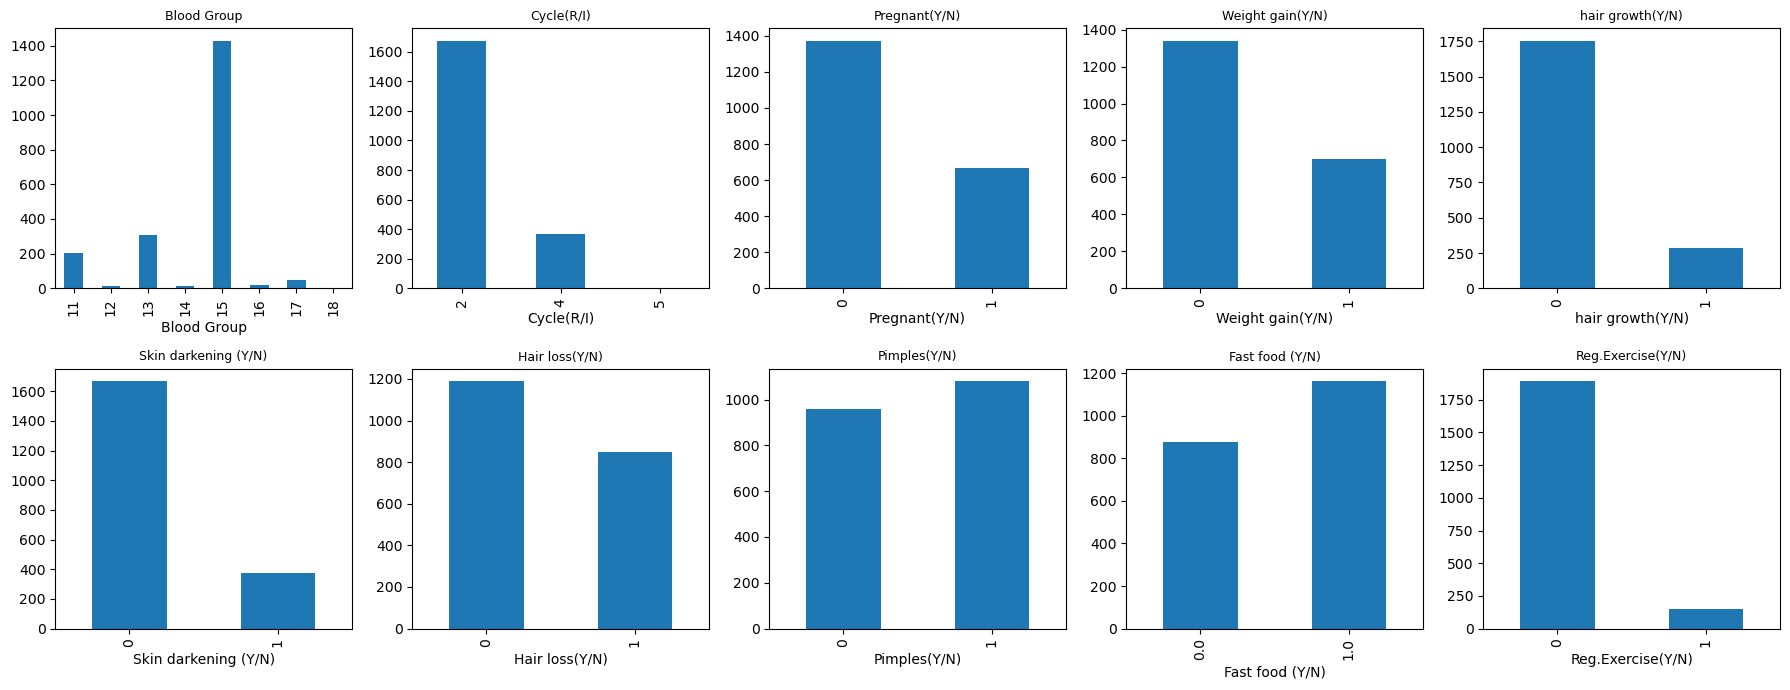

In [21]:
categorical_cols = ['Blood Group', 'Cycle(R/I)', 'Pregnant(Y/N)', 'Weight gain(Y/N)', 'hair growth(Y/N)',
                     'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)',
                     'Reg.Exercise(Y/N)']

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, c in zip(axes.flatten(), categorical_cols):
    df[c].value_counts().sort_index().plot(kind='bar', ax=ax)
    ax.set_title(c, fontsize=9)
plt.tight_layout()
plt.show()

In [22]:
rows = []
for c in continuous_cols:
    g0 = df_stat.loc[df_stat[target] == 0, c]
    g1 = df_stat.loc[df_stat[target] == 1, c]
    r, p = pointbiserialr(df_stat[target], df_stat[c])
    _, p_mw = mannwhitneyu(g0, g1)
    rows.append([c, r, p, p_mw, g0.mean(), g1.mean()])

num_vs_target = pd.DataFrame(rows, columns=['feature', 'point_biserial_r', 'p_value', 'p_value_mannwhitney',
                                             'mean_no_pcos', 'mean_pcos'])
num_vs_target['abs_r'] = num_vs_target['point_biserial_r'].abs()
num_vs_target = num_vs_target.sort_values('abs_r', ascending=False).reset_index(drop=True)
num_vs_target.round(4)

,feature,point_biserial_r,p_value,p_value_mannwhitney,mean_no_pcos,mean_pcos,abs_r
0,Follicle No. (R),0.6796,0.0000,0.0000,4.2037,11.4102,0.6796
1,Follicle No. (L),0.5363,0.0000,0.0000,4.6012,9.4026,0.5363
2,AMH(ng/mL),0.3312,0.0000,0.0000,3.1165,6.2852,0.3312
3,Cycle length(days),-0.2868,0.0000,0.0000,5.0655,4.3497,0.2868
4,Weight (Kg),0.2135,0.0000,0.0000,57.8748,62.3854,0.2135
5,Hip(inch),0.1911,0.0000,0.0000,37.3889,39.1229,0.1911
6,BMI,0.1896,0.0000,0.0000,23.7567,25.2594,0.1896
7,Waist(inch),0.1785,0.0000,0.0000,33.7712,35.1909,0.1785
8,Age (yrs),-0.1523,0.0000,0.0000,31.4504,29.6805,0.1523
9,Avg. F size (L) (mm),0.1304,0.0000,0.0000,14.8207,15.7509,0.1304


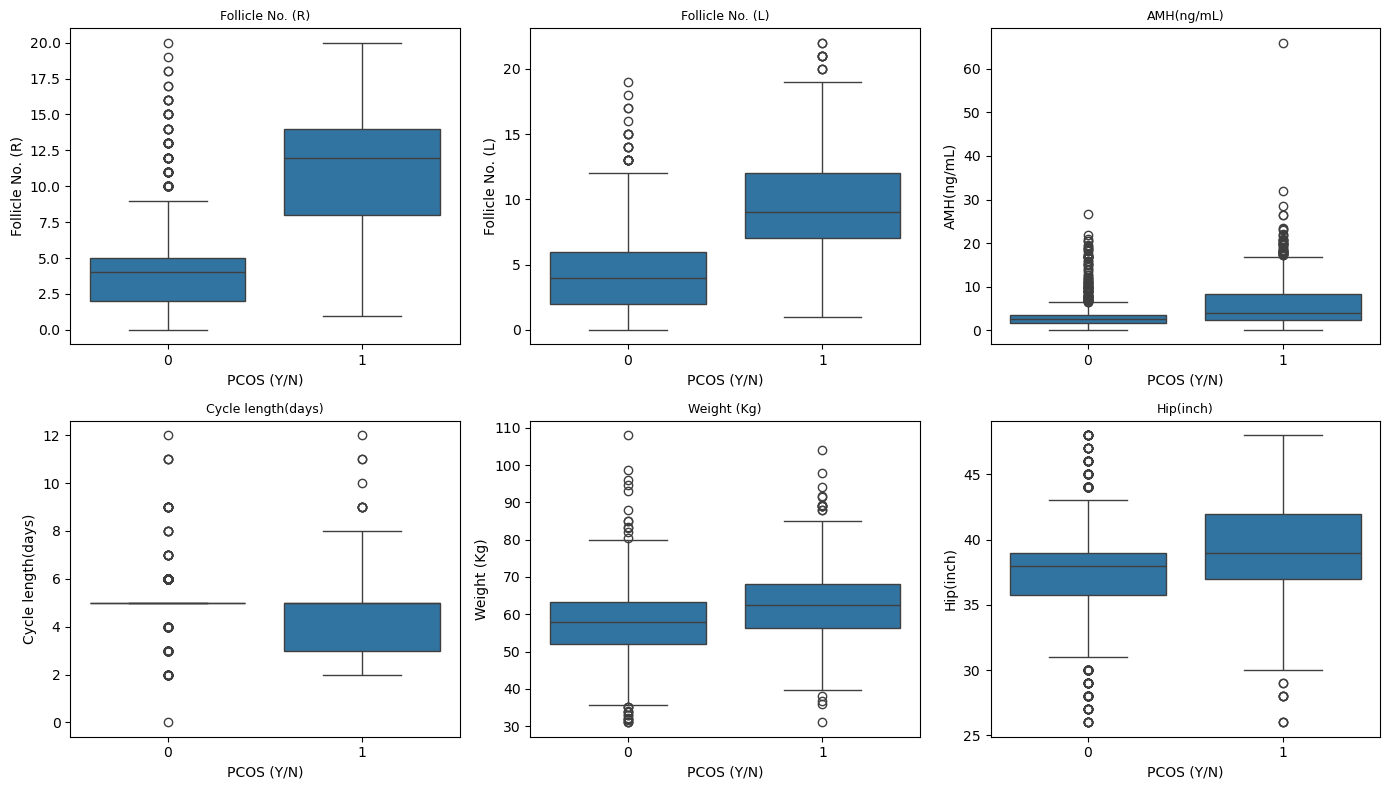

In [23]:
top_num = num_vs_target.head(6)['feature'].tolist()
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(axes.flatten(), top_num):
    sns.boxplot(x=df_stat[target], y=df_stat[c], ax=ax)
    ax.set_title(c, fontsize=9)
plt.tight_layout()
plt.show()

In [24]:
rows = []
for c in categorical_cols:
    table = pd.crosstab(df[c], df[target])
    chi2, p, dof, exp = chi2_contingency(table)
    n = table.sum().sum()
    cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    rows.append([c, chi2, p, cramers_v])

cat_vs_target = pd.DataFrame(rows, columns=['feature', 'chi2', 'p_value', 'cramers_v'])
cat_vs_target = cat_vs_target.sort_values('cramers_v', ascending=False).reset_index(drop=True)
cat_vs_target.round(4)

,feature,chi2,p_value,cramers_v
0,Skin darkening (Y/N),678.5607,0.0000,0.5766
1,hair growth(Y/N),531.1761,0.0000,0.5101
2,Cycle(R/I),473.2822,0.0000,0.4815
3,Weight gain(Y/N),470.0568,0.0000,0.4799
4,Fast food (Y/N),301.0799,0.0000,0.3841
5,Pimples(Y/N),207.4683,0.0000,0.3188
6,Hair loss(Y/N),96.5991,0.0000,0.2176
7,Blood Group,12.9206,0.0741,0.0796
8,Reg.Exercise(Y/N),11.1468,0.0008,0.0739
9,Pregnant(Y/N),0.0647,0.7992,0.0056


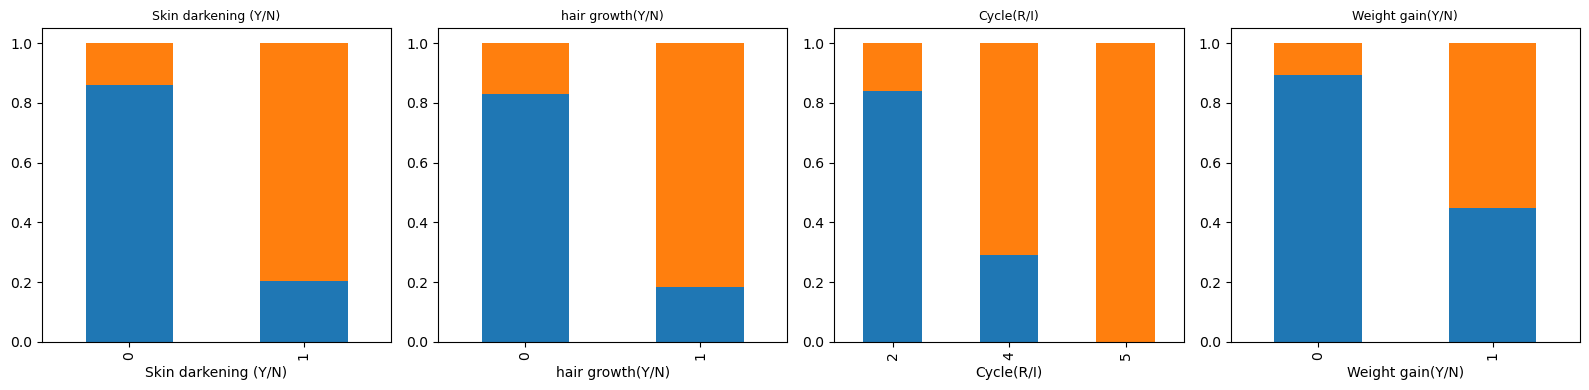

In [25]:
top_cat = cat_vs_target.head(4)['feature'].tolist()
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, top_cat):
    pd.crosstab(df[c], df[target], normalize='index').plot(kind='bar', stacked=True, ax=ax, legend=False)
    ax.set_title(c, fontsize=9)
plt.tight_layout()
plt.show()

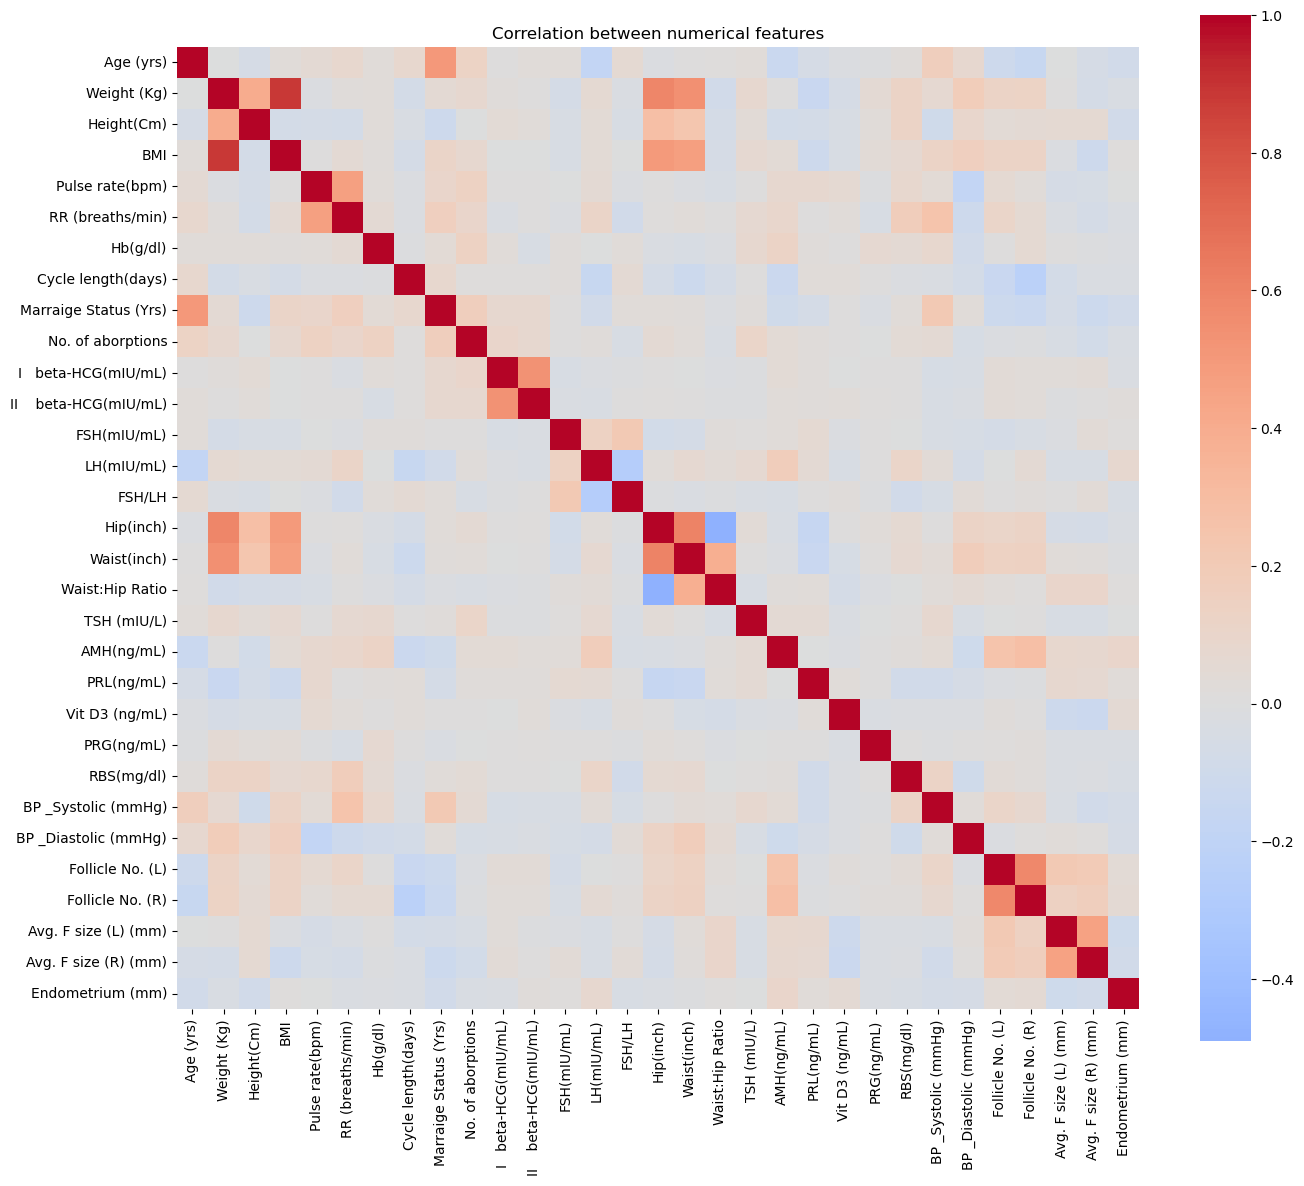

In [26]:
corr = df[continuous_cols].corr()
plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap='coolwarm', center=0, square=True)
plt.title('Correlation between numerical features')
plt.tight_layout()
plt.show()

In [27]:
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().reset_index()
pairs.columns = ['feature_1', 'feature_2', 'r']
pairs['abs_r'] = pairs['r'].abs()
pairs.sort_values('abs_r', ascending=False).head(10)

,feature_1,feature_2,r,abs_r
31,Weight (Kg),BMI,0.879823,0.879823
345,Hip(inch),Waist(inch),0.606619,0.606619
43,Weight (Kg),Hip(inch),0.587500,0.587500
455,Follicle No. (L),Follicle No. (R),0.579753,0.579753
44,Weight (Kg),Waist(inch),0.544063,0.544063
255,I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),0.537697,0.537697
7,Age (yrs),Marraige Status (Yrs),0.500047,0.500047
98,BMI,Hip(inch),0.495911,0.495911
346,Hip(inch),Waist:Hip Ratio,-0.489565,0.489565
99,BMI,Waist(inch),0.475274,0.475274


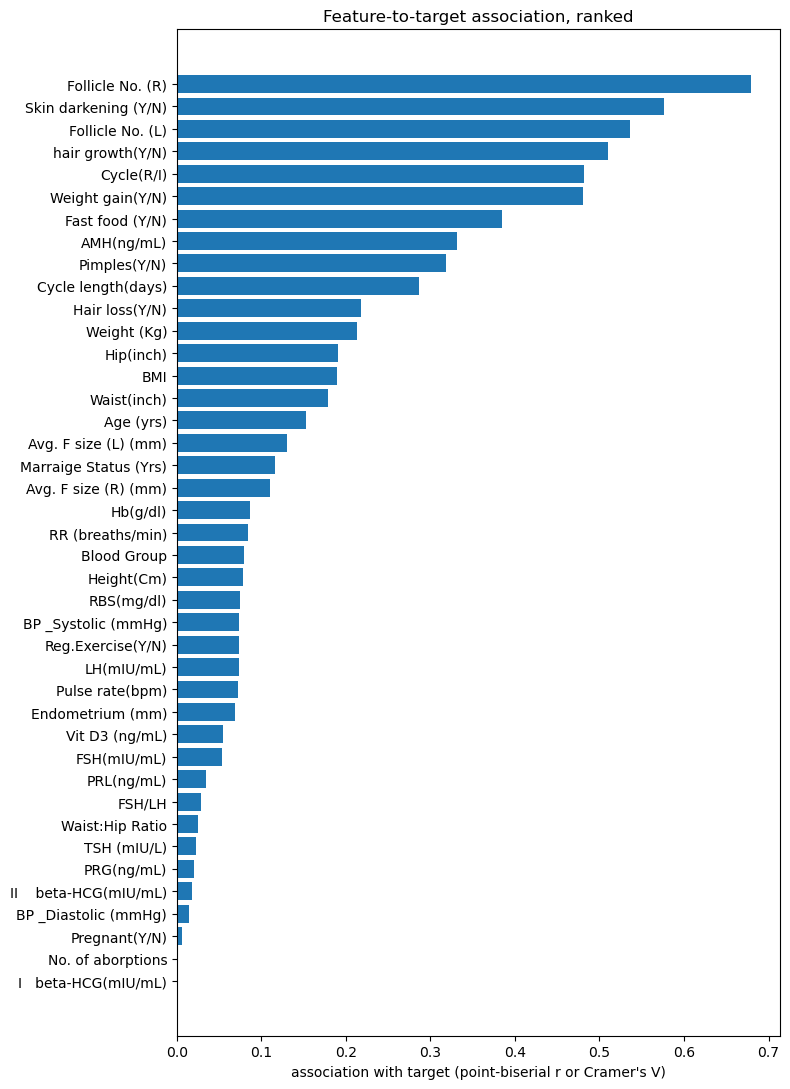

In [28]:
combined = pd.concat([
    num_vs_target[['feature', 'abs_r']].rename(columns={'abs_r': 'association'}),
    cat_vs_target[['feature', 'cramers_v']].rename(columns={'cramers_v': 'association'})
]).sort_values('association', ascending=False)

plt.figure(figsize=(8, 11))
plt.barh(combined['feature'], combined['association'])
plt.gca().invert_yaxis()
plt.xlabel('association with target (point-biserial r or Cramer\'s V)')
plt.title('Feature-to-target association, ranked')
plt.tight_layout()
plt.show()

In [29]:
X_vif = add_constant(df_stat[continuous_cols])
vif = pd.DataFrame()
vif['feature'] = X_vif.columns
vif['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
vif = vif[vif['feature'] != 'const'].sort_values('VIF', ascending=False).reset_index(drop=True)
vif

,feature,VIF
0,Weight (Kg),222.208945
1,BMI,187.965307
2,Hip(inch),68.796103
3,Waist(inch),61.070399
4,Height(Cm),50.740042
5,Waist:Hip Ratio,50.738523
6,Follicle No. (L),1.651545
7,Follicle No. (R),1.643712
8,Marraige Status (Yrs),1.473864
9,I beta-HCG(mIU/mL),1.435660


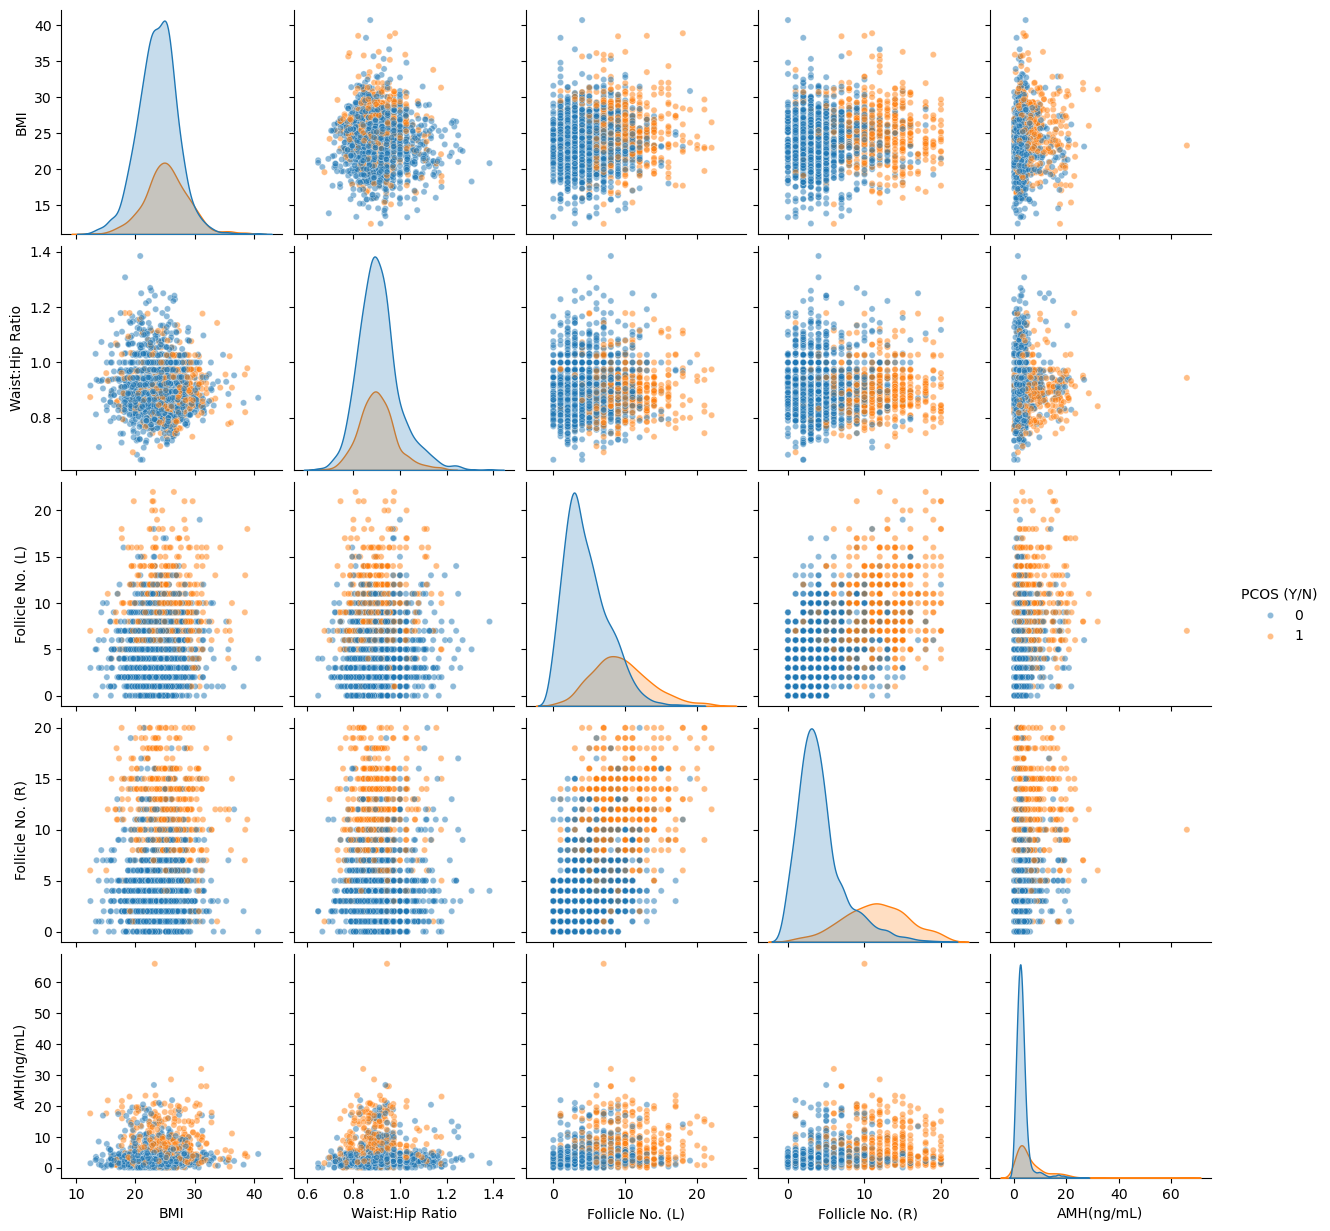

In [30]:
pairplot_cols = ['BMI', 'Waist:Hip Ratio', 'Follicle No. (L)', 'Follicle No. (R)', 'AMH(ng/mL)', target]
sns.pairplot(df_stat[pairplot_cols], hue=target, diag_kind='kde', plot_kws={'alpha': 0.5, 's': 20})
plt.show()

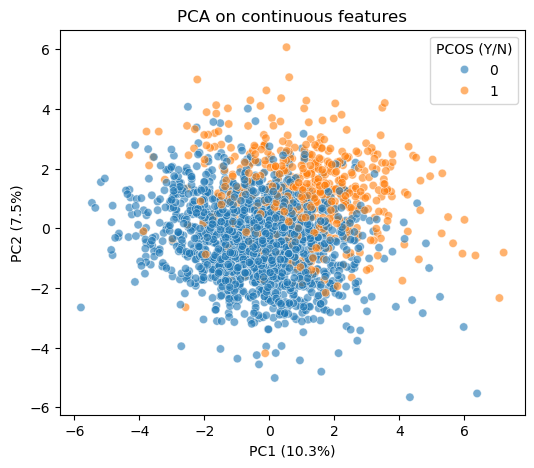

In [31]:
X_scaled = StandardScaler().fit_transform(df_stat[continuous_cols])
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(X_scaled)

plt.figure(figsize=(6, 5))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df_stat[target], alpha=0.6)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('PCA on continuous features')
plt.show()

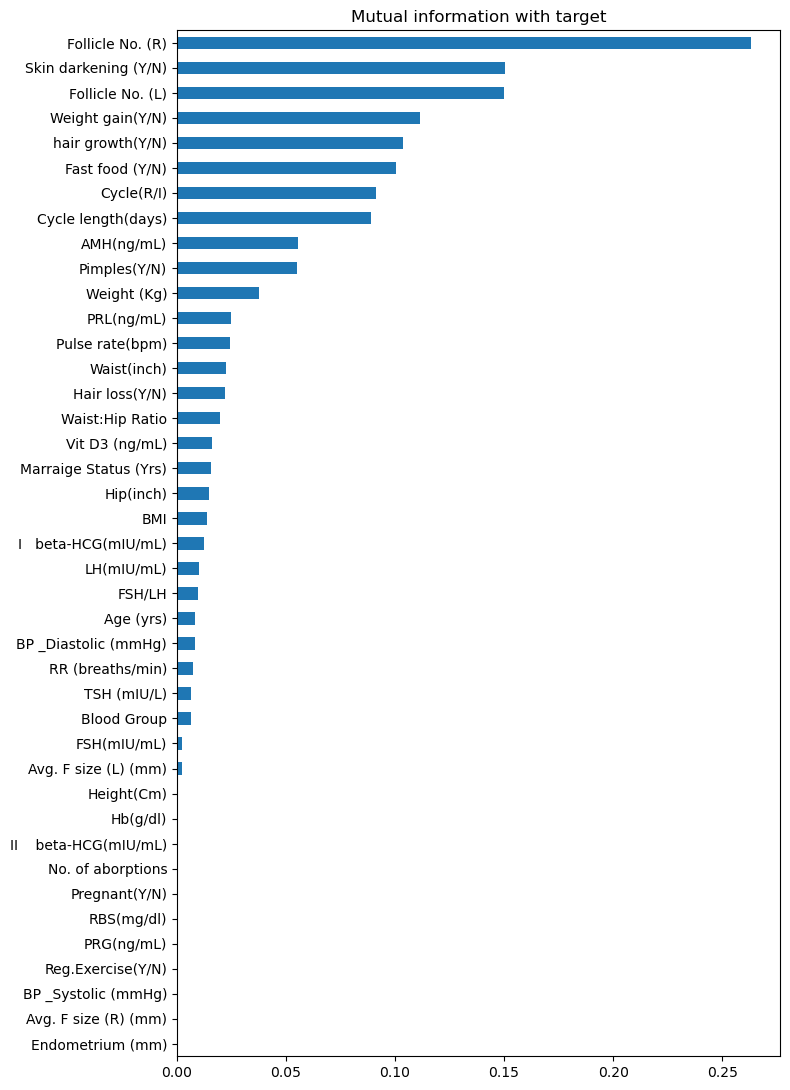

In [32]:
feature_cols = [c for c in df.columns if c not in (target, 'is_real')]
X = df_stat[feature_cols]
y = df_stat[target]

mi = mutual_info_classif(X, y, random_state=RANDOM_STATE)
mi_scores = pd.Series(mi, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(8, 11))
mi_scores.plot(kind='barh')
plt.gca().invert_yaxis()
plt.title('Mutual information with target')
plt.tight_layout()
plt.show()

In [33]:
X = df[feature_cols]
y = df[target]
cols = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
pos_w = (y_train == 0).sum() / (y_train == 1).sum()

rf = Pipeline([('imputer', SimpleImputer(strategy='median')),
               ('model', RandomForestClassifier(n_estimators=500, min_samples_leaf=2,
                                                class_weight='balanced_subsample', random_state=SEED, n_jobs=-1))])
xgb_clf = Pipeline([('imputer', SimpleImputer(strategy='median')),
                    ('model', xgb.XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                                                colsample_bytree=0.8, scale_pos_weight=pos_w, eval_metric='logloss',
                                                random_state=SEED, n_jobs=-1))])
rf.fit(X_train, y_train)
xgb_clf.fit(X_train, y_train)

def score(name, model, Xt, yt):
    p = model.predict_proba(Xt)[:, 1]
    return {'model': name, 'n_rows': len(yt), 'auc': roc_auc_score(yt, p),
            'recall': recall_score(yt, p >= 0.5), 'precision': precision_score(yt, p >= 0.5)}

real_test = df.loc[X_test.index, 'is_real'].to_numpy()
rows = []
for name, m in [('Random Forest', rf), ('XGBoost', xgb_clf)]:
    rows.append(score(f'{name} | all test rows', m, X_test, y_test))
    rows.append(score(f'{name} | REAL test rows only', m, X_test[real_test], y_test[real_test]))
test_scores = pd.DataFrame(rows).set_index('model').round(3)
display(test_scores)

rf_auc = test_scores.loc['Random Forest | all test rows', 'auc']
xgb_auc = test_scores.loc['XGBoost | all test rows', 'auc']

def perm_importance_of(model):
    r = permutation_importance(model, X_test, y_test, scoring='roc_auc', n_repeats=20,
                               random_state=SEED, n_jobs=-1)
    return pd.Series(r.importances_mean, index=cols).sort_values(ascending=False)

rf_importance = perm_importance_of(rf)
xgb_importance = perm_importance_of(xgb_clf)
print(f'RF test ROC-AUC: {rf_auc:.4f}   XGBoost test ROC-AUC: {xgb_auc:.4f}')

,n_rows,auc,recall,precision
model,,,,
Random Forest | all test rows,409,0.973,0.858,0.901
Random Forest | REAL test rows only,106,0.956,0.852,0.852
XGBoost | all test rows,409,0.975,0.896,0.848
XGBoost | REAL test rows only,106,0.953,0.889,0.750


RF test ROC-AUC: 0.9730   XGBoost test ROC-AUC: 0.9750


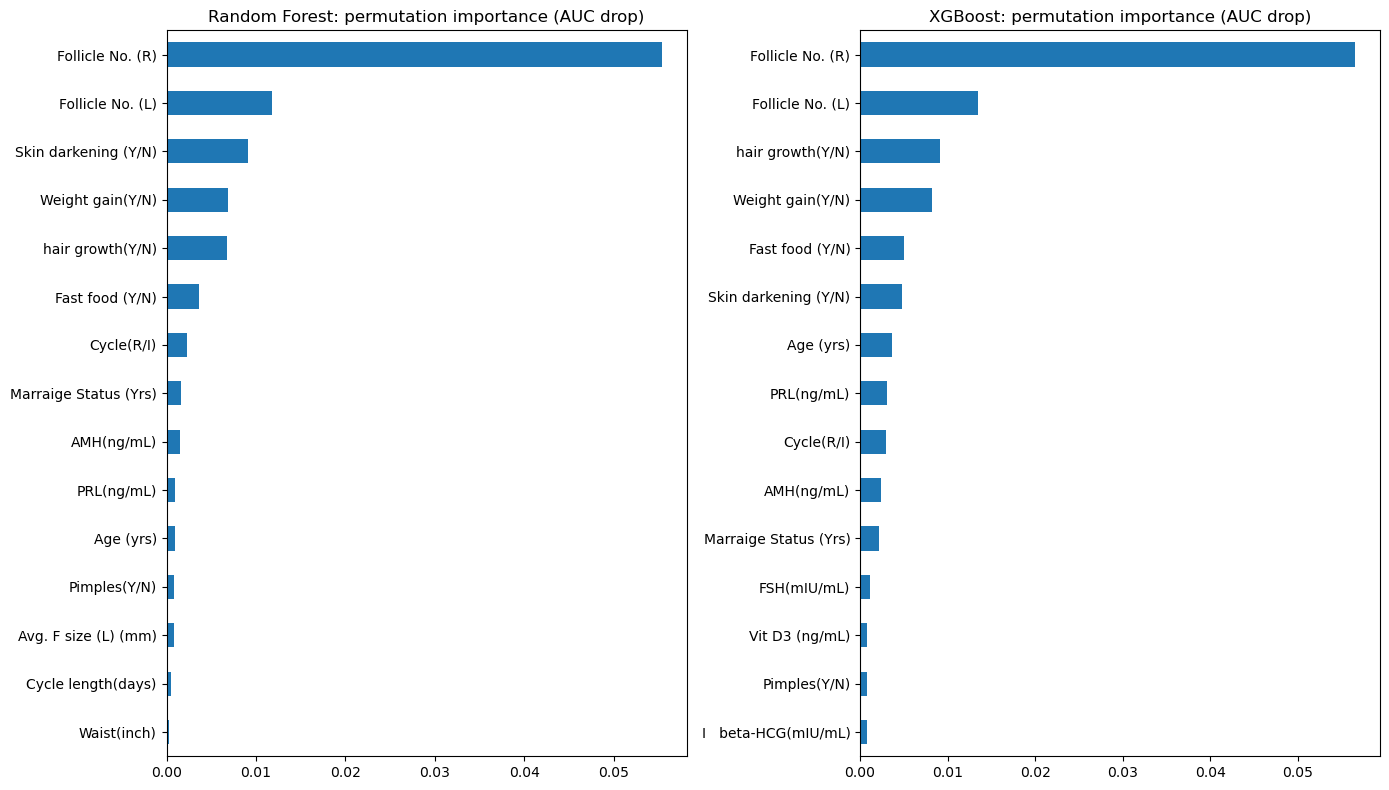

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
rf_importance.head(15)[::-1].plot(kind='barh', ax=axes[0], title='Random Forest: permutation importance (AUC drop)')
xgb_importance.head(15)[::-1].plot(kind='barh', ax=axes[1], title='XGBoost: permutation importance (AUC drop)')
plt.tight_layout()
plt.show()

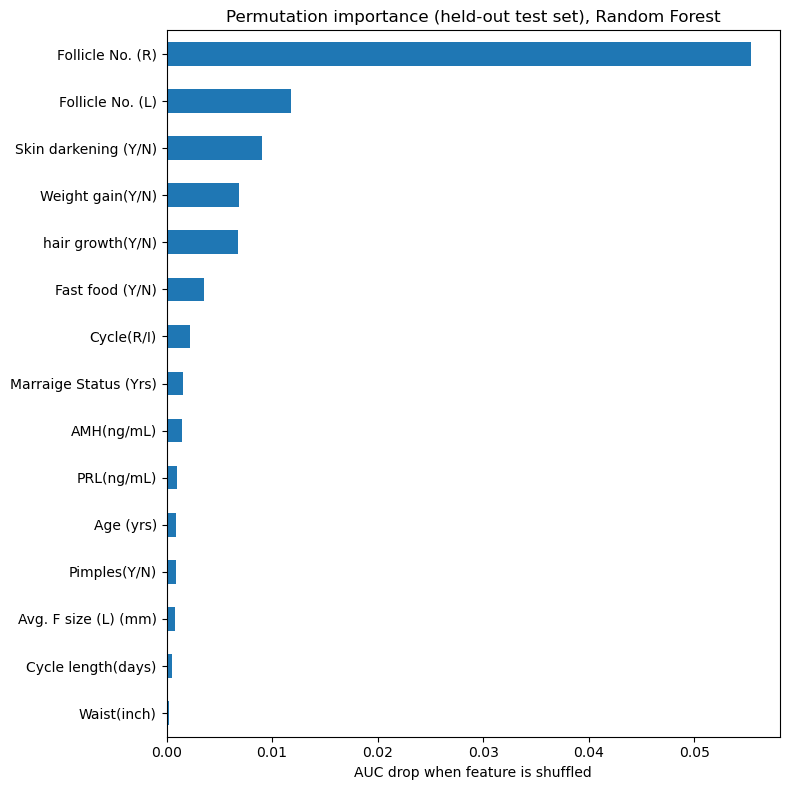

In [35]:
perm_importance = rf_importance

perm_importance.head(15)[::-1].plot(kind='barh', figsize=(8, 8))
plt.title('Permutation importance (held-out test set), Random Forest')
plt.xlabel('AUC drop when feature is shuffled')
plt.tight_layout()
plt.show()

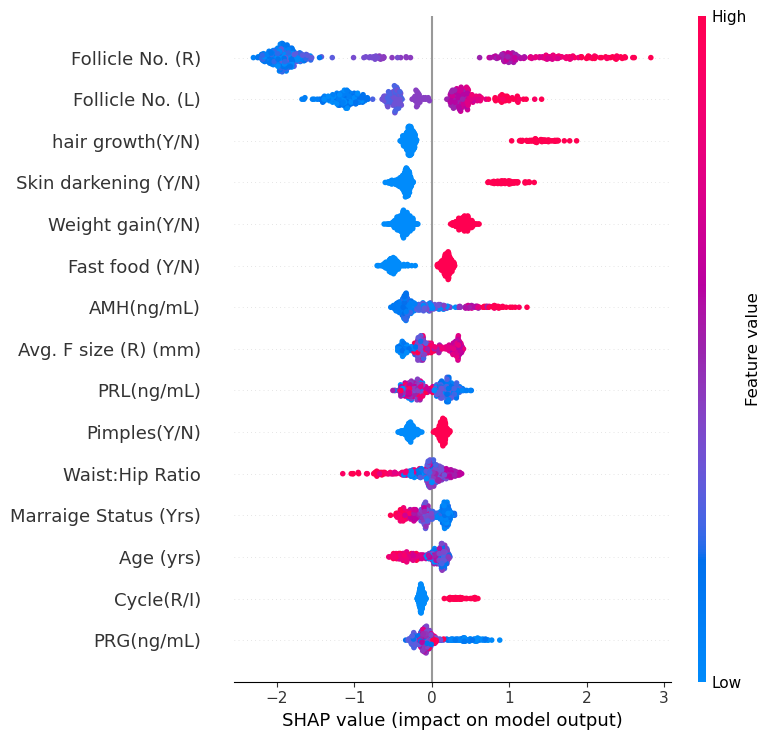

In [36]:
if SHAP_AVAILABLE:
    X_test_prep = pd.DataFrame(xgb_clf[:-1].transform(X_test), columns=cols, index=X_test.index)
    explainer = shap.TreeExplainer(xgb_clf[-1])
    shap_values = explainer.shap_values(X_test_prep)
    shap.summary_plot(shap_values, X_test_prep, show=False, max_display=15)
    plt.tight_layout()
    plt.show()
else:
    print('shap is not installed in this environment, skipping this plot.')

In [37]:
diagnostic_features = ['Follicle No. (L)', 'Follicle No. (R)', 'hair growth(Y/N)', 'Skin darkening (Y/N)',
                       'Weight gain(Y/N)', 'Cycle(R/I)']
rf_diag = Pipeline([('imputer', SimpleImputer(strategy='median')),
                    ('model', RandomForestClassifier(n_estimators=500, min_samples_leaf=2,
                                                     class_weight='balanced_subsample', random_state=SEED, n_jobs=-1))])
rf_diag.fit(X_train[diagnostic_features], y_train)
diag_auc = roc_auc_score(y_test, rf_diag.predict_proba(X_test[diagnostic_features])[:, 1])
print(f'ROC-AUC using only diagnostic-criteria-like features: {diag_auc:.4f}')
print(f'ROC-AUC using all features (Random Forest):           {rf_auc:.4f}')

ROC-AUC using only diagnostic-criteria-like features: 0.9553
ROC-AUC using all features (Random Forest):           0.9730


In [38]:
df_fe = df.drop(columns='is_real')

df_fe['BMI_category'] = pd.cut(df_fe['BMI'], bins=[0, 18.5, 25, 30, 100],
                                labels=['Underweight', 'Normal', 'Overweight', 'Obese'])

symptom_cols = ['Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)']
df_fe['Symptom_count'] = df_fe[symptom_cols].sum(axis=1)

df_fe['Total_follicle_count'] = df_fe['Follicle No. (L)'] + df_fe['Follicle No. (R)']
df_fe['Follicle_asymmetry'] = (df_fe['Follicle No. (L)'] - df_fe['Follicle No. (R)']).abs()

df_fe[['BMI_category', 'Symptom_count', 'Total_follicle_count', 'Follicle_asymmetry']].head()

,BMI_category,Symptom_count,Total_follicle_count,Follicle_asymmetry
0,Normal,2,24,0
1,Normal,3,20,0
2,Underweight,3,22,0
3,Overweight,5,32,6
4,Normal,0,4,2


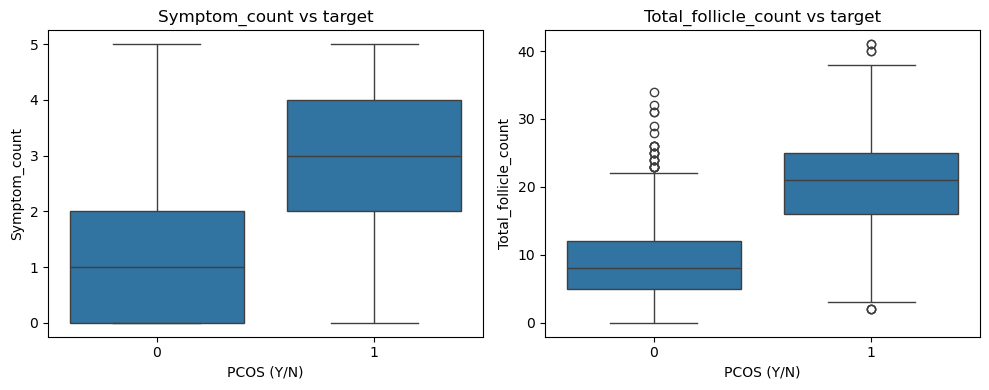

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(x=df_fe[target], y=df_fe['Symptom_count'], ax=axes[0])
sns.boxplot(x=df_fe[target], y=df_fe['Total_follicle_count'], ax=axes[1])
axes[0].set_title('Symptom_count vs target')
axes[1].set_title('Total_follicle_count vs target')
plt.tight_layout()
plt.show()

In [40]:
rank = pd.concat([
    num_vs_target[['feature', 'abs_r']].rename(columns={'abs_r': 'association'}),
    cat_vs_target[['feature', 'cramers_v']].rename(columns={'cramers_v': 'association'})
], ignore_index=True)

rank = rank.merge(vif[['feature', 'VIF']], on='feature', how='left')
rank = rank.merge(rf_importance.rename('perm_importance'), left_on='feature', right_index=True, how='left')

def priority(row):
    if row['VIF'] > 10:
        return 'redundant / check before linear model'
    if row['association'] > 0.3:
        return 'strong'
    if row['association'] > 0.15:
        return 'moderate'
    return 'weak'

rank['priority'] = rank.apply(priority, axis=1)
rank = rank.sort_values('perm_importance', ascending=False).reset_index(drop=True)
rank.round(4)

,feature,association,VIF,perm_importance,priority
0,Follicle No. (R),0.6796,1.6437,0.0554,strong
1,Follicle No. (L),0.5363,1.6515,0.0118,strong
2,Skin darkening (Y/N),0.5766,NaN,0.0091,strong
3,Weight gain(Y/N),0.4799,NaN,0.0068,strong
4,hair growth(Y/N),0.5101,NaN,0.0068,strong
5,Fast food (Y/N),0.3841,NaN,0.0036,strong
6,Cycle(R/I),0.4815,NaN,0.0022,strong
7,Marraige Status (Yrs),0.1163,1.4739,0.0016,weak
8,AMH(ng/mL),0.3312,1.2078,0.0015,strong
9,PRL(ng/mL),0.0343,1.0776,0.0009,weak


In [41]:
rank['priority'].value_counts()

priority
weak                                     23
strong                                    9
redundant / check before linear model     6
moderate                                  3
Name: count, dtype: int64